# Stage 3 | Can a Latent World Model Be Compared with Its Simulator?

**Stage 2 showed that generated future frames did not preserve our tube-pickup policies.** Before asking the paired question on the MuJoCo tube task, this notebook runs it on a stack that already matches: TD-MPC2, its PickCube policy, and the SAPIEN/PhysX simulator.

One frozen policy starts from the same states in two branches. The simulator branch receives the next physical state. The world-model branch receives the next predicted latent state and does not generate future images. The aim is to see how those two judgments are produced and compared. [Notebook 4](04_latent_tube_policy_evaluation.ipynb) asks that procedure again for a tube controller and a tube-specific model. The PickCube policy and weights stay here.

Simulator official success was **19/20**. The model reward proxy was **17/20**. The two missed successes are kept in the paired records below.

[Stage 1 · ACT tube pickup](01_act_imitation_learning.ipynb) · [Stage 2 · native WorldGym evaluation](02_worldgym_policy_evaluation.ipynb)


## 1. Why this comparison follows the tube result
**Situation.** [Stage 1](01_act_imitation_learning.ipynb) trained ACT policies that pick up a centrifuge tube in MuJoCo. [Stage 2](02_worldgym_policy_evaluation.ipynb) asked whether native WorldGym could evaluate those fixed policies by generating future camera frames. With simulator images the policies scored 8/10 and 10/10. Replaying the actions produced inside the native observation loops scored 0/10 for both.

**Task.** Ask a paired-evaluation question where the world model does not generate future images. PickCube already has a matched simulator, latent model, and policy. From identical starts, compare the fixed policy in the physics simulator with the same policy running on predicted latent states.

The diagrams below separate the two representations of the future. TD-MPC2 predicts internal states and rewards. WorldGym generates future visual observations; Stage 2 tested that image loop on the tube task. The PickCube numbers do not replace the Stage 2 result.


## Overview of TD-MPC2: Our Fixed-Policy Evaluation

Read left to right: initial observation and encoding, repeated policy/dynamics steps, then predicted rewards. The symbol key distinguishes observed state, latent state, policy proposal, immediate reward, and long-term value. The Q-value belongs to full TD-MPC2; our fixed-policy evaluation uses no MPC planning or terminal Q-value.

![Overview of TD-MPC2: Our Fixed-Policy Evaluation](media/stage3/overview_tdmpc2_symbols_en.png)
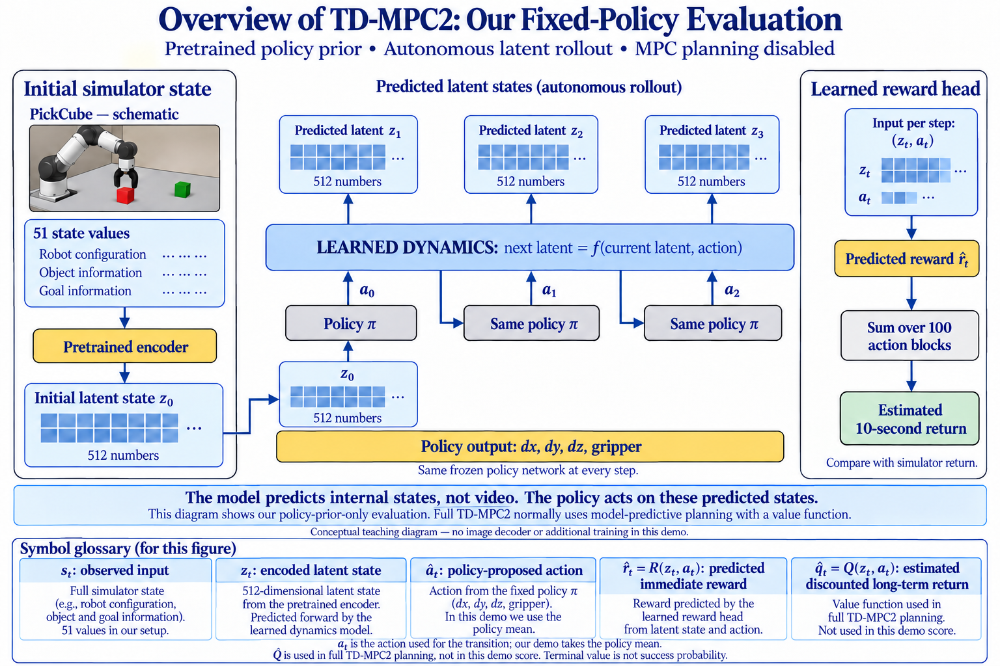

## Overview of WorldGym

For comparison, WorldGym feeds generated future images back to the same visual policy and uses a VLM to score the generated rollout. Stage 2 measured that image loop on the MuJoCo tube task. This diagram explains the architecture. The PickCube experiment below predicts latent states and rewards, and it does not generate future frames.

![Overview of WorldGym](media/stage3/overview_worldgym_en.png)
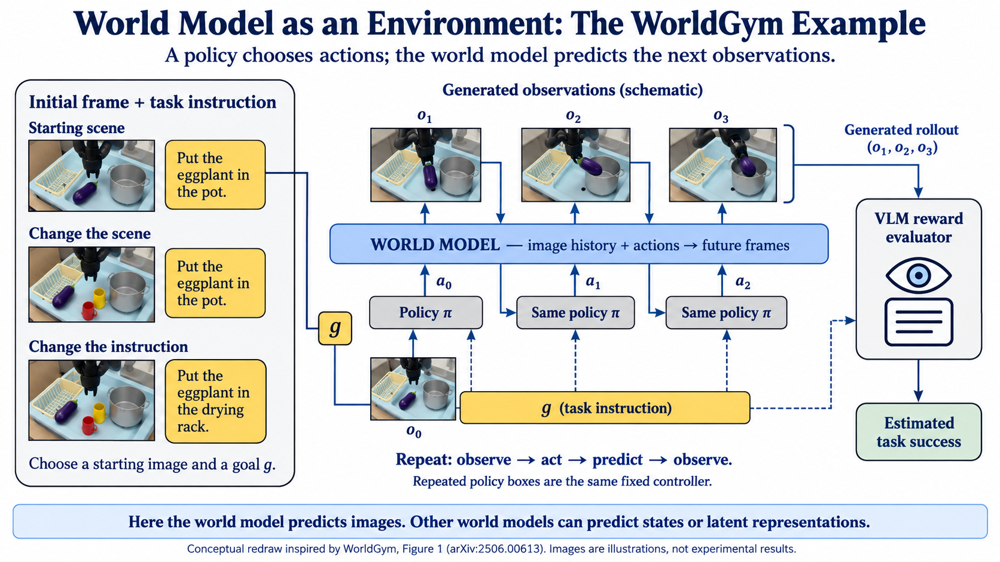

## 2. A fair comparison: same policy, same starts
**Action.** Keep the pretrained policy weights fixed. Change only how its next input is produced.

![Same policy, two feedback loops](media/stage3/same_policy_two_environments_en.png)
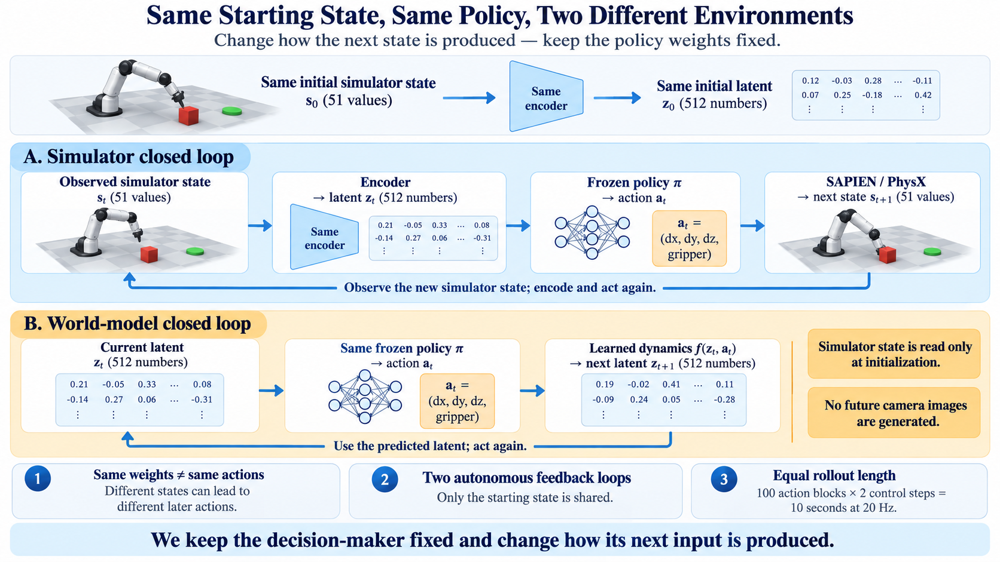

### Follow one action through each loop
PickCube runs in SAPIEN with the PhysX backend. Stages 1 and 2 run in MuJoCo. The robot, the camera observations, the action, and the success rule differ, so this policy is not a tube policy.

| Simulator loop | World-model loop |
|---|---|
| Observed 51-value state → encoder → latent | Initial state → same encoder → initial latent |
| Frozen policy chooses an action | Same frozen policy chooses an action |
| SAPIEN/PhysX computes the next observed state | Learned dynamics predicts the next latent |
| Encode the new observation and act again | Act from the predicted latent and repeat |

The policy outputs **dx, dy, dz, gripper**. Fixed weights do not imply fixed actions: later actions can differ when the two loops encounter different states. MPC planning is disabled; we use the pretrained policy prior's mean action.

Each run has **100 action blocks**, with each action repeated for two control steps: 200 steps at 20 Hz = **10 seconds**. The world-model branch reads simulator state only at initialization.

### Two endpoint judgments
| Judgment | Rule at the end of the run |
|---|---|
| Simulator official success | Cube-to-goal distance ≤ 0.025 m **and** maximum arm joint speed ≤ 0.2 |
| Model reward-proxy success | Predicted reward for the **last action block > 8** |

The model predicts a reward, not a geometric success label or success probability. A successful control step has reward 5; a two-step block can reach 10. Threshold 8 was fixed before the 20-start evaluation. It is not a threshold on total ten-second return.

### Load the paired records
“20 paired starts” means 20 initial scenes, each run once through each loop. The following code opens their saved result table and media.

In [1]:
%matplotlib inline
from pathlib import Path
import json, hashlib
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image, Video, HTML
ROOT = Path.cwd().resolve()
if not (ROOT / "evidence" / "stage3").exists():
    ROOT = ROOT.parent
DATA = ROOT / "evidence" / "stage3"
MEDIA = ROOT / "media" / "stage3"
summary = json.loads((DATA / "summary.json").read_text(encoding="utf-8"))
rows = summary["records"]
print(f"Loaded {len(rows)} paired evaluation records: one simulator run and one model rollout per start.")


Loaded 20 paired evaluation records: one simulator run and one model rollout per start.


## 3. Four paired cases: watch, measure, compare
We show two joint successes, one joint failure, and one missed success. Four examples do not imply four outcome categories: **no simulator-failure/model-proxy-success case occurred** in these 20 starts.

For each case: watch the simulator trajectory, inspect six moments and the official criteria, then compare the model's reward/latent/action animation. Simulator videos re-render verified SAPIEN physical trajectories with TinyRenderer. Model animations display saved numerical predictions, not generated camera frames.

**Animation guide:** orange = predicted reward; dashed blue = simulator reference added afterward; center = 512 latent numbers arranged into a heatmap; right = policy action. The simulator reference is not fed into the autonomous model loop.

### A. Agreement on success — seed 920100
| Simulator official | Model reward proxy |
|---|---|
| SUCCESS | SUCCESS |

**Watch:** red cube, green goal marker, gray gripper. The six close-ups show 0, 0.5, 1, 3, 6, and 10 seconds.

[Simulator video](media/stage3/sim_success.mp4)


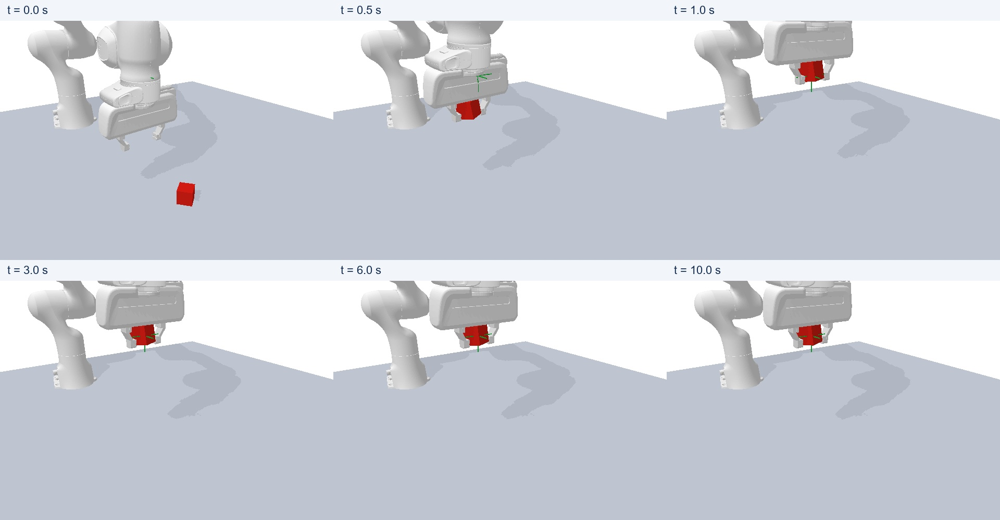

In [2]:
display(Video(str(MEDIA / "sim_success.mp4"), embed=True, width=1000))
display(Image(filename=str(MEDIA / "sim_success_timeline.jpg"), width=1100))

**Measure:** both curves must be at or below their red boundary at the final step. They need not stay below it throughout the movement.

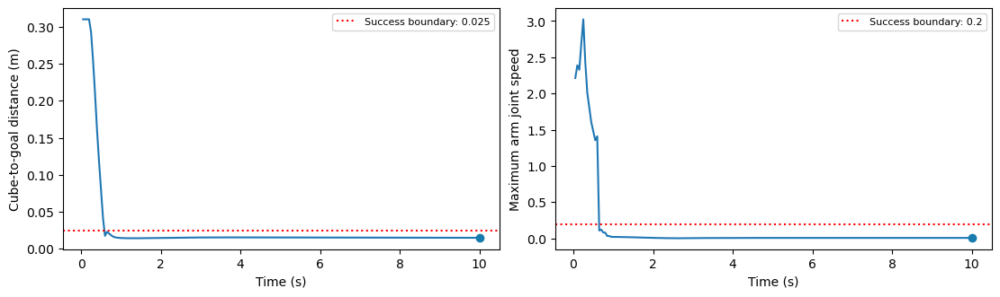

In [3]:
episode = np.load(DATA / "920100.npz")
time = np.arange(1, 201) / 20
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), constrained_layout=True)
for ax, key, boundary, ylabel in [(axes[0], "sim_goal_distance", .025, "Cube-to-goal distance (m)"), (axes[1], "sim_arm_max_speed", .2, "Maximum arm joint speed")]:
    ax.plot(time, episode[key])
    ax.axhline(boundary, linestyle=":", color="red", label=f"Success boundary: {boundary}")
    ax.scatter([time[-1]], [episode[key][-1]], color="#167cad", zorder=3)
    ax.set(xlabel="Time (s)", ylabel=ylabel)
    ax.legend(fontsize=8)
plt.show()

**Compare:** follow the predicted reward over time; use the last block to read the proxy outcome.

[Model animation](media/stage3/wm_success_animation.mp4)


In [4]:
display(Video(str(MEDIA / "wm_success_animation.mp4"), embed=True, width=1100))
display(HTML(f"<table><tr><th>Final distance (m)</th><th>Final maximum joint speed</th><th>Final model reward</th></tr><tr><td>{episode['sim_goal_distance'][-1]:.5f}</td><td>{episode['sim_arm_max_speed'][-1]:.5f}</td><td>{episode['wm_rewards'][-1]:.3f}</td></tr></table>"))

Final distance (m),Final maximum joint speed,Final model reward
0.01488,0.00665,9.985


**Takeaway:** Both endpoint judgments indicate success.

### B. Another agreement on success — seed 920102
| Simulator official | Model reward proxy |
|---|---|
| SUCCESS | SUCCESS |

**Watch:** red cube, green goal marker, gray gripper. The six close-ups show 0, 0.5, 1, 3, 6, and 10 seconds.

[Simulator video](media/stage3/sim_success_second.mp4)


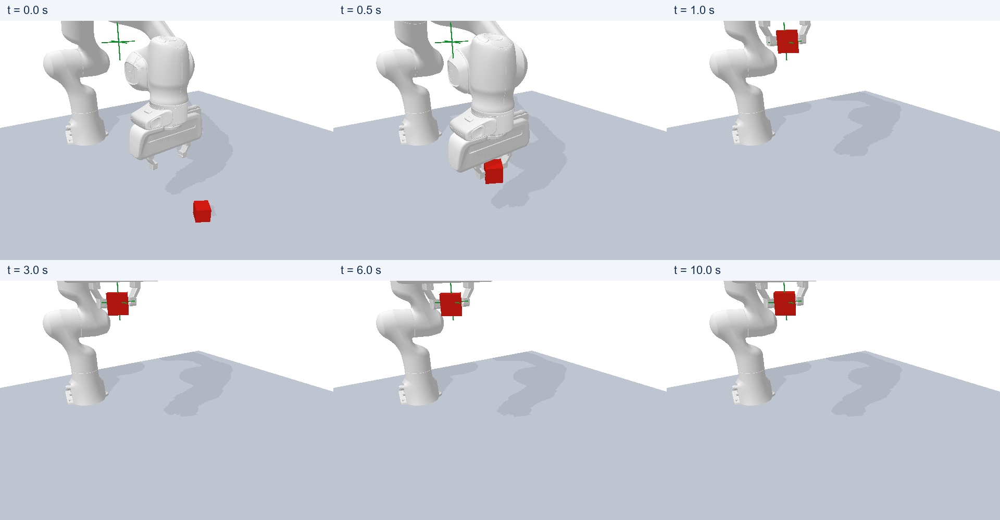

In [5]:
display(Video(str(MEDIA / "sim_success_second.mp4"), embed=True, width=1000))
display(Image(filename=str(MEDIA / "sim_success_second_timeline.jpg"), width=1100))

**Measure:** both curves must be at or below their red boundary at the final step. They need not stay below it throughout the movement.

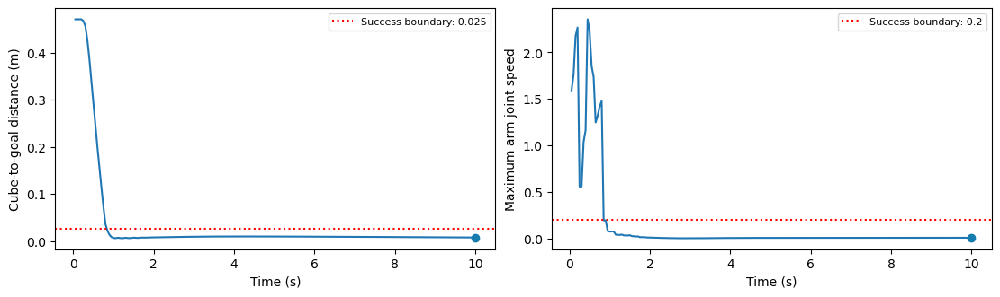

In [6]:
episode = np.load(DATA / "920102.npz")
time = np.arange(1, 201) / 20
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), constrained_layout=True)
for ax, key, boundary, ylabel in [(axes[0], "sim_goal_distance", .025, "Cube-to-goal distance (m)"), (axes[1], "sim_arm_max_speed", .2, "Maximum arm joint speed")]:
    ax.plot(time, episode[key])
    ax.axhline(boundary, linestyle=":", color="red", label=f"Success boundary: {boundary}")
    ax.scatter([time[-1]], [episode[key][-1]], color="#167cad", zorder=3)
    ax.set(xlabel="Time (s)", ylabel=ylabel)
    ax.legend(fontsize=8)
plt.show()

**Compare:** follow the predicted reward over time; use the last block to read the proxy outcome.

[Model animation](media/stage3/wm_success_second_animation.mp4)


In [7]:
display(Video(str(MEDIA / "wm_success_second_animation.mp4"), embed=True, width=1100))
display(HTML(f"<table><tr><th>Final distance (m)</th><th>Final maximum joint speed</th><th>Final model reward</th></tr><tr><td>{episode['sim_goal_distance'][-1]:.5f}</td><td>{episode['sim_arm_max_speed'][-1]:.5f}</td><td>{episode['wm_rewards'][-1]:.3f}</td></tr></table>"))

Final distance (m),Final maximum joint speed,Final model reward
0.00737,0.00769,9.939


**Takeaway:** A second starting condition also produces matching success judgments.

### C. Agreement on failure — seed 920118
| Simulator official | Model reward proxy |
|---|---|
| FAILURE | FAILURE |

**Watch:** red cube, green goal marker, gray gripper. The six close-ups show 0, 0.5, 1, 3, 6, and 10 seconds.

[Simulator video](media/stage3/sim_failure.mp4)


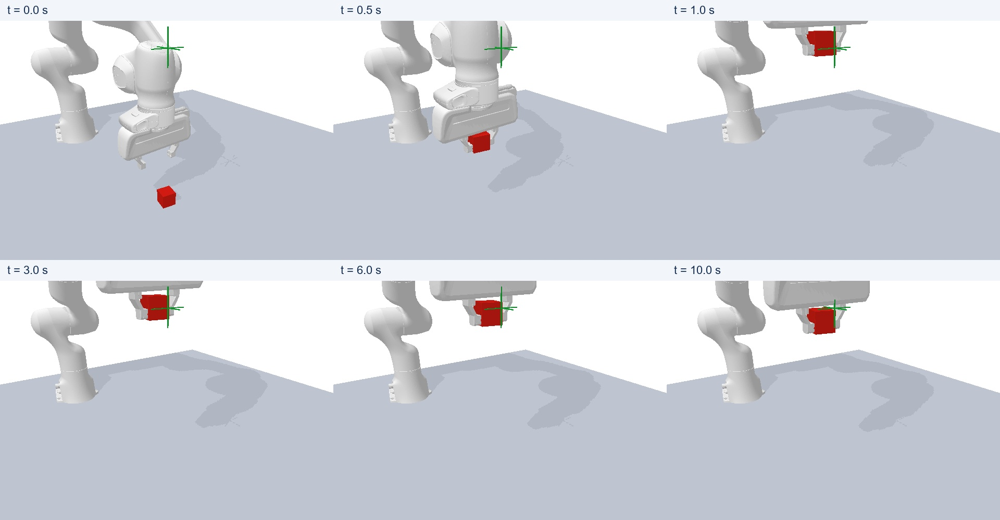

In [8]:
display(Video(str(MEDIA / "sim_failure.mp4"), embed=True, width=1000))
display(Image(filename=str(MEDIA / "sim_failure_timeline.jpg"), width=1100))

**Measure:** both curves must be at or below their red boundary at the final step. They need not stay below it throughout the movement.

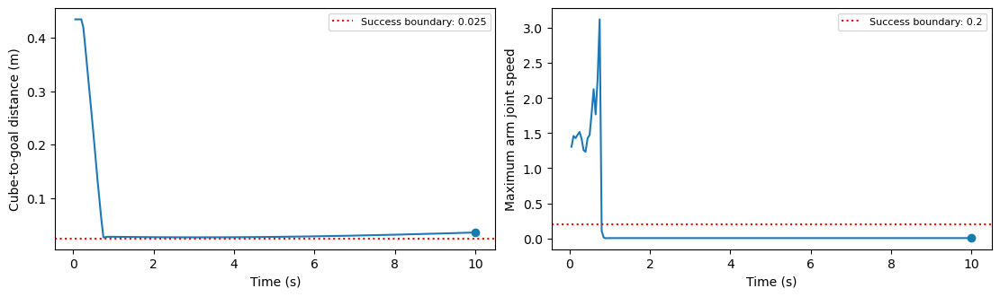

In [9]:
episode = np.load(DATA / "920118.npz")
time = np.arange(1, 201) / 20
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), constrained_layout=True)
for ax, key, boundary, ylabel in [(axes[0], "sim_goal_distance", .025, "Cube-to-goal distance (m)"), (axes[1], "sim_arm_max_speed", .2, "Maximum arm joint speed")]:
    ax.plot(time, episode[key])
    ax.axhline(boundary, linestyle=":", color="red", label=f"Success boundary: {boundary}")
    ax.scatter([time[-1]], [episode[key][-1]], color="#167cad", zorder=3)
    ax.set(xlabel="Time (s)", ylabel=ylabel)
    ax.legend(fontsize=8)
plt.show()

**Compare:** follow the predicted reward over time; use the last block to read the proxy outcome.

[Model animation](media/stage3/wm_shared_failure_animation.mp4)


In [10]:
display(Video(str(MEDIA / "wm_shared_failure_animation.mp4"), embed=True, width=1100))
display(HTML(f"<table><tr><th>Final distance (m)</th><th>Final maximum joint speed</th><th>Final model reward</th></tr><tr><td>{episode['sim_goal_distance'][-1]:.5f}</td><td>{episode['sim_arm_max_speed'][-1]:.5f}</td><td>{episode['wm_rewards'][-1]:.3f}</td></tr></table>"))

Final distance (m),Final maximum joint speed,Final model reward
0.03579,0.00325,1.838


**Takeaway:** The simulated arm stops, but the cube remains too far from the goal. The model proxy also indicates failure; agreement alone does not identify the same failure mechanism.

### D. A missed success — seed 920101
| Simulator official | Model reward proxy |
|---|---|
| SUCCESS | FAILURE |

**Watch:** red cube, green goal marker, gray gripper. The six close-ups show 0, 0.5, 1, 3, 6, and 10 seconds.

[Simulator video](media/stage3/sim_for_wm_failure.mp4)


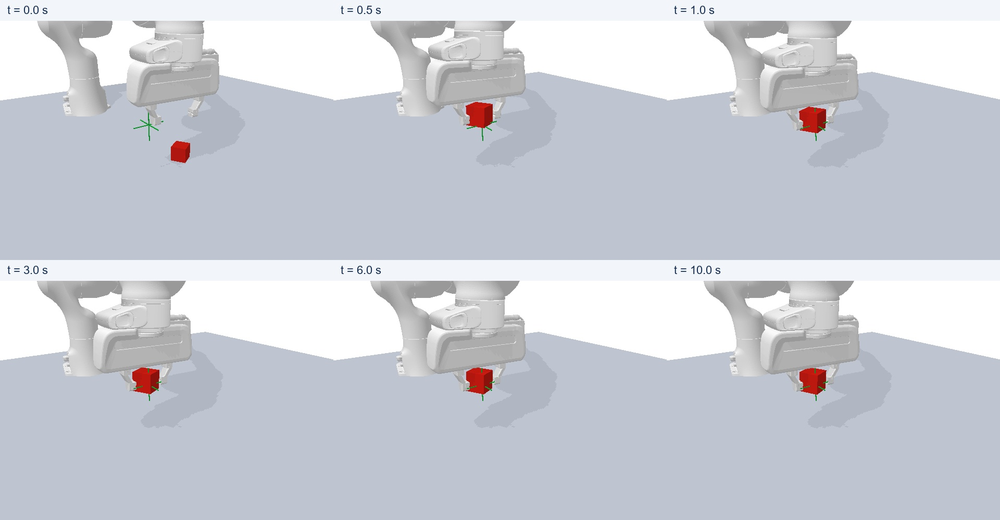

In [11]:
display(Video(str(MEDIA / "sim_for_wm_failure.mp4"), embed=True, width=1000))
display(Image(filename=str(MEDIA / "sim_for_wm_failure_timeline.jpg"), width=1100))

**Measure:** both curves must be at or below their red boundary at the final step. They need not stay below it throughout the movement.

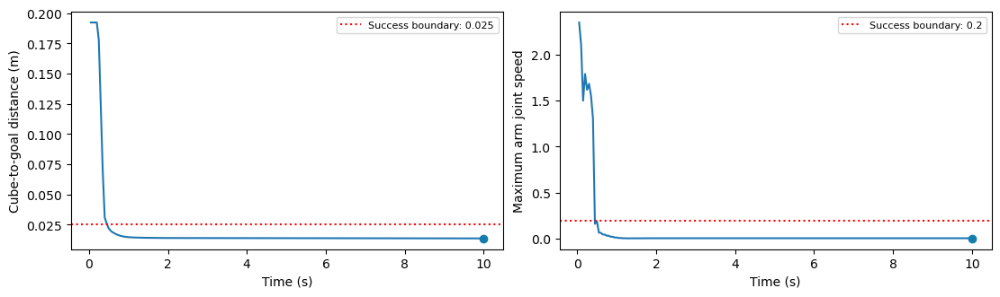

In [12]:
episode = np.load(DATA / "920101.npz")
time = np.arange(1, 201) / 20
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), constrained_layout=True)
for ax, key, boundary, ylabel in [(axes[0], "sim_goal_distance", .025, "Cube-to-goal distance (m)"), (axes[1], "sim_arm_max_speed", .2, "Maximum arm joint speed")]:
    ax.plot(time, episode[key])
    ax.axhline(boundary, linestyle=":", color="red", label=f"Success boundary: {boundary}")
    ax.scatter([time[-1]], [episode[key][-1]], color="#167cad", zorder=3)
    ax.set(xlabel="Time (s)", ylabel=ylabel)
    ax.legend(fontsize=8)
plt.show()

**Compare:** follow the predicted reward over time; use the last block to read the proxy outcome.

[Model animation](media/stage3/wm_failure_animation.mp4)


In [13]:
display(Video(str(MEDIA / "wm_failure_animation.mp4"), embed=True, width=1100))
display(HTML(f"<table><tr><th>Final distance (m)</th><th>Final maximum joint speed</th><th>Final model reward</th></tr><tr><td>{episode['sim_goal_distance'][-1]:.5f}</td><td>{episode['sim_arm_max_speed'][-1]:.5f}</td><td>{episode['wm_rewards'][-1]:.3f}</td></tr></table>"))

Final distance (m),Final maximum joint speed,Final model reward
0.01366,0.00589,1.709


**Takeaway:** The simulator meets both official conditions, but the model predicts a final reward below the proxy threshold. This is a missed simulator success.

## 4. Results across all 20 starts
**Result.** The four cases teach the mechanism; the following statistics include **all 20 starts**. Cases were chosen in frozen seed order within each category, with the second joint success chosen after the first.

Simulator official,Model proxy,Count
Success,Success,17
Success,Failure,2
Failure,Success,0
Failure,Failure,1


Simulator official success: 19/20; model proxy success: 17/20; agreement: 18/20
Mean cumulative reward: simulator 935.11; model 918.71; MAE 19.11


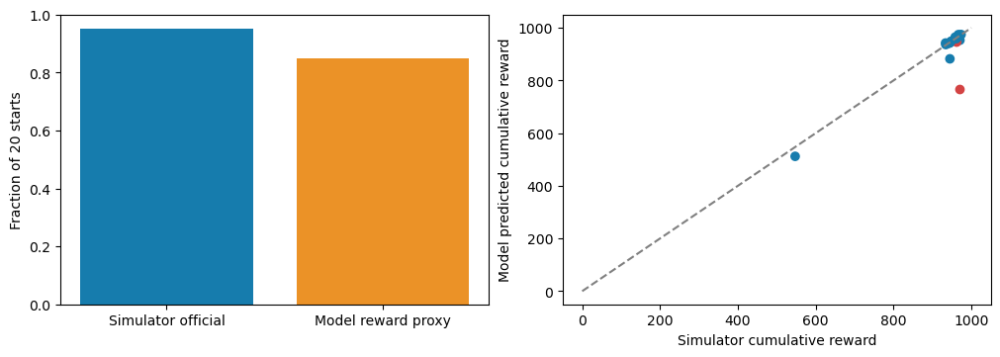

In [14]:
sim = np.array([r["sim_success"] for r in rows], dtype=bool)
wm = np.array([r["wm_success_proxy"] for r in rows], dtype=bool)
sr = np.array([r["sim_return"] for r in rows])
wr = np.array([r["wm_return_100"] for r in rows])
counts = [int((sim & wm).sum()), int((sim & ~wm).sum()), int((~sim & wm).sum()), int((~sim & ~wm).sum())]
display(HTML("<table><tr><th>Simulator official</th><th>Model proxy</th><th>Count</th></tr>" + "".join(f"<tr><td>{a}</td><td>{b}</td><td>{n}</td></tr>" for (a,b),n in zip([('Success','Success'),('Success','Failure'),('Failure','Success'),('Failure','Failure')],counts)) + "</table>"))
print(f"Simulator official success: {sim.sum()}/20; model proxy success: {wm.sum()}/20; agreement: {(sim==wm).sum()}/20")
print(f"Mean cumulative reward: simulator {sr.mean():.2f}; model {wr.mean():.2f}; MAE {np.abs(sr-wr).mean():.2f}")
fig,axes=plt.subplots(1,2,figsize=(10,3.5),constrained_layout=True)
axes[0].bar(['Simulator official','Model reward proxy'],[sim.mean(),wm.mean()],color=['#167cad','#eb9227'])
axes[0].set(ylim=(0,1),ylabel='Fraction of 20 starts')
axes[1].scatter(sr,wr,c=np.where(sim==wm,'#167cad','#d34343'))
axes[1].plot([0,1000],[0,1000],'--',color='gray')
axes[1].set(xlabel='Simulator cumulative reward',ylabel='Model predicted cumulative reward')
plt.show()
assert counts == [17,2,0,1]

The paired closed-loop demonstration is complete: most judgments agree and two simulator successes are missed. With 19 simulator successes, an always-success guess would match 19/20 labels, compared with 18/20 for this proxy. Agreement alone therefore does not establish a reliable success detector. We preserve the mismatches without making further PickCube ranking experiments a prerequisite for migration.

The original 20-start evaluation took **18.8 seconds**, excluding setup/debugging. The ten seconds in each video denote control time, not compute time.

## 5. What this stage shows

| STAR | This stage |
|---|---|
| Situation | Stage 2's generated frames did not preserve tube pickup, so the next test uses a world model that does not require future camera images. |
| Task | Compare one fixed policy in a latent world model and in its physics simulator, from the same starts. |
| Action | Reuse the pretrained TD-MPC2 PickCube components, disable MPC, and run the simulator loop and the latent loop separately. |
| Result | **19/20** simulator official successes and **17/20** reward-proxy successes. Two simulator successes are missed. Agreement is 18/20. |

PickCube is an intermediate environment. Official success here means the cube is within 0.025 m of the goal and the maximum arm joint speed is at most 0.2. The tube rule remains body height above 0.925 m and left-finger contact with the cap. This notebook does not evaluate the Stage 1 ACT policies, and it does not change the Stage 2 replay result of 0/10.

A tube-task counterpart still needs a model matched to the MuJoCo observations and the official tube check. The PickCube weights are not assumed to transfer.

**One-sentence report:** After native image rollouts failed to evaluate the tube policies, a latent world model on PickCube agreed with its simulator on 18 of 20 paired starts.

[Back to Stage 2](02_worldgym_policy_evaluation.ipynb)


## Appendix. Inspect the bundled evidence

The next cell checks the 20 saved trajectories in `evidence/stage3/` against the fingerprints in `summary.json`. It also checks that the teaching replays in `media/stage3/` match the original observations and rewards. It does not rerun SAPIEN or train a model.

[Back to Stage 2](02_worldgym_policy_evaluation.ipynb)


In [15]:
assert len(rows)==20 and len({r['seed'] for r in rows})==20
for r in rows:
    assert hashlib.sha256((DATA/f"{r['seed']}.npz").read_bytes()).hexdigest()==r['npz_sha256']
for name in ['selection_and_replay.json','star_extra_replay.json']:
    for replay in json.loads((MEDIA/name).read_text())['replays']:
        assert replay['observation_max_abs_error']==0 and replay['reward_max_abs_error']==0
print('All 20 original records match their saved fingerprints. Teaching replays match original observations and rewards.')

All 20 original records match their saved fingerprints. Teaching replays match original observations and rewards.
